# Phase 5 — Individual classifiers

**Goal:** understand how each model family behaves on our features, pick the best single
model, and make the first Kaggle submission.

**Setup (from Phase 4):** calm dropped, `raw_loudness_db` and `speech_s` dropped, and the same
grouped folds and macro F1 for every model.

**Score to beat:** logistic regression at **0.824 overall, 0.489 RAVDESS, 0.967 TESS**.

**How we pick a winner:** highest overall macro F1, because that's the competition metric.
Watch RAVDESS too, since it's the honest score for unseen speakers. Remember that any
difference smaller than `fold_std` (about 0.02) is noise.

Running the whole notebook takes a few minutes. The tuning cell in section 4 is the slowest.

In [ ]:
import sys
sys.path.insert(0, '../src')

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from submission import load_test_data, write_submission
from validation import DROP_FEATURES, evaluate, folds, load_training_data, pipeline, report

X, y, meta = load_training_data(drop_features=DROP_FEATURES)
print(f'{X.shape[0]} clips x {X.shape[1]} features | dropped: {DROP_FEATURES} | calm excluded')

4048 clips x 256 features | dropped: ['raw_loudness_db', 'speech_s'] | calm excluded


## 1. The five models

| Model | How it decides | Strength | Weakness |
|---|---|---|---|
| **Logistic regression** | Gives each emotion a weighted sum of the features; the highest sum wins. Boundaries are straight lines (flat planes). | Fast, stable, hard to overfit | Can't capture curved patterns or feature interactions |
| **k-NN** (k nearest neighbours) | Finds the *k* most similar training clips and takes a majority vote | No real training; easy to understand | "Similar" is measured by distance, which gets unreliable with many features |
| **SVM, RBF kernel** | Draws boundaries that keep the widest possible margin between emotions; the RBF kernel lets them curve | Often the strongest on medium-sized tables of features | Needs scaling and tuning |
| **Decision tree** | Asks a series of yes/no questions, each about one feature ("is `mfcc_01_mean` > 12?") | Easy to read | Overfits easily: it can memorise the training data |
| **Random forest** | Hundreds of trees, each trained on a random subset of the clips and features, then they vote | Robust, needs little tuning | Slower; harder to interpret. It's already an **ensemble** (a preview of Phase 6) |

## 2. Every model with default settings

Start with the defaults. Tuning comes later, so we can see how much it actually adds.

In [2]:
MODELS = {
    'logreg':        LogisticRegression(max_iter=5000),
    'knn':           KNeighborsClassifier(),
    'svm_rbf':       SVC(kernel='rbf'),
    'decision_tree': DecisionTreeClassifier(random_state=0),
    'random_forest': RandomForestClassifier(n_estimators=300, random_state=0),
}
default_rows = []
for name, model in MODELS.items():
    scores, _ = evaluate(pipeline(model), X, y, meta, name=name)
    default_rows.append(scores)
defaults = pd.DataFrame(default_rows).set_index('model').round(3)
defaults

,macro_f1,fold_std,ravdess_f1,tess_f1
model,,,,
logreg,0.824,0.019,0.489,0.967
knn,0.803,0.016,0.367,0.993
svm_rbf,0.854,0.020,0.521,0.996
decision_tree,0.732,0.018,0.298,0.920
random_forest,0.832,0.022,0.441,0.997


## 3. Why scaling matters, for some models

Our features live on very different ranges: `mfcc_00_mean` is around −200, `zcr_mean` around
0.05 and `f0_median_hz` around 200. `pipeline()` rescales every feature to mean 0 and std 1.

- **k-NN and SVM** decide by **distance** between clips. Without scaling, the features with
  big numbers dominate the distance, and the small ones are effectively ignored.
- **Trees** compare **one feature at a time** against a threshold. Stretching a feature
  doesn't change which threshold splits it best, so scaling shouldn't matter.

The cell below removes the scaler (but keeps the imputer for the 5 clips with no pitch)
and re-scores three of the models.

In [3]:
scaling_rows = []
for name in ['knn', 'svm_rbf', 'random_forest']:
    unscaled = make_pipeline(SimpleImputer(strategy='median'), clone(MODELS[name]))
    s, _ = evaluate(unscaled, X, y, meta, name=name)
    scaling_rows.append({'model': name,
                         'with scaling': defaults.loc[name, 'macro_f1'],
                         'without scaling': round(s['macro_f1'], 3)})
pd.DataFrame(scaling_rows).set_index('model')

,with scaling,without scaling
model,,
knn,0.803,0.527
svm_rbf,0.854,0.234
random_forest,0.832,0.832


## 4. Bias vs variance: one decision tree, many depths

`max_depth` limits how many yes/no questions a tree may ask in a row.

- **Too shallow → high bias (underfitting):** the model is too simple to capture the
  patterns, so it does badly on *both* training and validation data.
- **Too deep → high variance (overfitting):** the model memorises the training clips,
  including their quirks. It looks perfect on training data but worse on new data.

The plot shows the score on the **training folds** (data the model learned from) and on
the **validation folds** (unseen data). The gap between the two lines is overfitting.

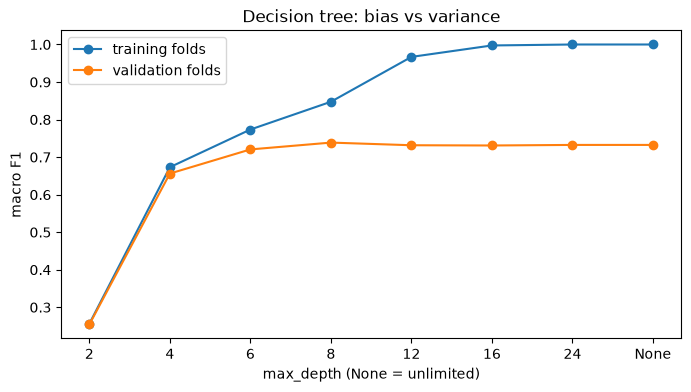

In [4]:
depth_search = GridSearchCV(pipeline(DecisionTreeClassifier(random_state=0)),
                            {'decisiontreeclassifier__max_depth': [2, 4, 6, 8, 12, 16, 24, None]},
                            cv=folds(meta), scoring='f1_macro', return_train_score=True, n_jobs=-1)
depth_search.fit(X, y)
curve = pd.DataFrame(depth_search.cv_results_)
depths = [str(d) for d in curve['param_decisiontreeclassifier__max_depth']]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depths, curve['mean_train_score'], marker='o', label='training folds')
ax.plot(depths, curve['mean_test_score'], marker='o', label='validation folds')
ax.set(xlabel='max_depth (None = unlimited)', ylabel='macro F1', title='Decision tree: bias vs variance')
ax.legend()
plt.show()

## 5. Light hyperparameter tuning

**Hyperparameters** are settings we choose rather than learn from data. `GridSearchCV` tries
every combination in a small grid, scores each one with **our grouped folds**, and keeps
the best.

| Model | Hyperparameter | What it controls |
|---|---|---|
| logreg, SVM | `C` | How hard to fit the training data. Higher = fits harder, with more risk of overfitting |
| SVM | `gamma` | How far each training clip's influence reaches. Higher = more local, wigglier boundaries |
| k-NN | `n_neighbors`, `weights` | How many neighbours vote, and whether closer ones count more |
| tree | `max_depth`, `min_samples_leaf` | How deep it may grow, and the minimum number of clips in each final group |
| forest | `max_features`, `min_samples_leaf` | How many features each split may consider, and the leaf size |

This is the slow cell: it fits about 160 models.

In [5]:
GRIDS = {
    'logreg':        {'logisticregression__C': [0.01, 0.1, 1, 10]},
    'knn':           {'kneighborsclassifier__n_neighbors': [1, 5, 15, 31],
                      'kneighborsclassifier__weights': ['uniform', 'distance']},
    'svm_rbf':       {'svc__C': [1, 10, 100], 'svc__gamma': ['scale', 0.001]},
    'decision_tree': {'decisiontreeclassifier__max_depth': [8, 12, 16, None],
                      'decisiontreeclassifier__min_samples_leaf': [1, 5, 20]},
    'random_forest': {'randomforestclassifier__max_features': ['sqrt', 0.3],
                      'randomforestclassifier__min_samples_leaf': [1, 3]},
}
tuned_rows, tuned_preds, best_params = [], {}, {}
for name, grid in GRIDS.items():
    search = GridSearchCV(pipeline(MODELS[name]), grid, cv=folds(meta), scoring='f1_macro', n_jobs=-1)
    search.fit(X, y)
    best_params[name] = {key.split('__')[1]: value for key, value in search.best_params_.items()}
    scores, tuned_preds[name] = evaluate(search.best_estimator_, X, y, meta, name=name)
    tuned_rows.append(scores)
    print(f'{name:14s} best settings: {best_params[name]}')

tuned = pd.DataFrame(tuned_rows).set_index('model').round(3)
comparison = defaults[['macro_f1', 'ravdess_f1', 'tess_f1']].join(
    tuned[['macro_f1', 'fold_std', 'ravdess_f1', 'tess_f1']], lsuffix='_default', rsuffix='_tuned')
comparison['tuning_gain'] = comparison['macro_f1_tuned'] - comparison['macro_f1_default']
comparison.sort_values('macro_f1_tuned', ascending=False)

logreg         best settings: {'C': 0.1}
knn            best settings: {'n_neighbors': 15, 'weights': 'distance'}
svm_rbf        best settings: {'C': 10, 'gamma': 'scale'}
decision_tree  best settings: {'max_depth': 8, 'min_samples_leaf': 1}
random_forest  best settings: {'max_features': 'sqrt', 'min_samples_leaf': 1}


/var/folders/7f/g7pcy1j52mddcmhq46xk916r0000gn/T/ipykernel_86207/225978130.py:21: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  comparison = defaults[['macro_f1', 'ravdess_f1', 'tess_f1']].join(


,macro_f1_default,ravdess_f1_default,tess_f1_default,macro_f1_tuned,fold_std,ravdess_f1_tuned,tess_f1_tuned,tuning_gain
model,,,,,,,,
svm_rbf,0.854,0.521,0.996,0.858,0.016,0.538,0.995,0.004
logreg,0.824,0.489,0.967,0.836,0.020,0.500,0.981,0.012
random_forest,0.832,0.441,0.997,0.832,0.022,0.441,0.997,0.000
knn,0.803,0.367,0.993,0.819,0.014,0.414,0.995,0.016
decision_tree,0.732,0.298,0.920,0.738,0.012,0.306,0.921,0.006


**A caution: the tuned scores are slightly optimistic.** We tried many settings and kept the
one that scored best *on these same folds*. Some of its advantage is luck on these
particular folds. This is called **overfitting the validation set**. With grids this small
the effect is small, but it's why a tuning gain smaller than `fold_std` shouldn't be trusted.

## 6. The best single model

Picked by tuned overall macro F1. Below are its per-emotion results and confusion matrix,
from the out-of-fold predictions.

Best single model: svm_rbf {'C': 10, 'gamma': 'scale'}
CV macro F1 0.858 | RAVDESS 0.538 | TESS 0.995
              precision    recall  f1-score   support

       angry      0.867     0.895     0.881       592
     disgust      0.852     0.867     0.859       592
        fear      0.814     0.880     0.846       592
       happy      0.858     0.824     0.841       592
     neutral      0.873     0.875     0.874       496
         sad      0.828     0.807     0.818       592
   surprised      0.920     0.858     0.888       592

    accuracy                          0.858      4048
   macro avg      0.859     0.858     0.858      4048
weighted avg      0.859     0.858     0.858      4048



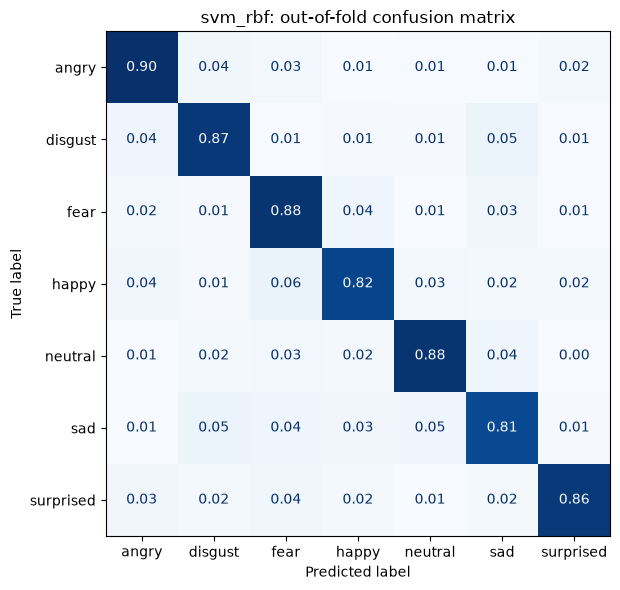

In [6]:
best_name = tuned['macro_f1'].idxmax()
print(f"Best single model: {best_name} {best_params[best_name]}")
print(f"CV macro F1 {tuned.loc[best_name, 'macro_f1']} | RAVDESS {tuned.loc[best_name, 'ravdess_f1']} "
      f"| TESS {tuned.loc[best_name, 'tess_f1']}")
report(y, tuned_preds[best_name], meta, title=f'{best_name}: out-of-fold confusion matrix')

## 7. First Kaggle submission

During cross-validation, each model trained on 80% of the data. For the submission we
**retrain the best model on 100%** of it, then predict the 201 test clips.
`write_submission` checks the format (201 rows, columns `Id,Label`, only the 7 valid labels)
before saving to `submissions/`.

In [7]:
final_model = pipeline(clone(MODELS[best_name]).set_params(**best_params[best_name]))
final_model.fit(X, y)

X_test, test_ids = load_test_data(X.columns)
test_pred = final_model.predict(X_test)
path = write_submission(test_ids, test_pred, f'phase5_{best_name}')
print(f'Wrote {path}')
pd.Series(test_pred).value_counts()

Wrote /Users/shardjosh19/Code/audio-project-kaggle/submissions/phase5_svm_rbf.csv


fear         39
neutral      32
happy        31
angry        28
sad          26
surprised    25
disgust      20
Name: count, dtype: int64

**To submit**, run this in your terminal from the project root (it uses your Kaggle token).
Replace the file name with the one printed above:

```bash
kaggle competitions submit -c audio-speech-emotion-classification -f submissions/phase5_<model>.csv -m "Phase 5: best single model"
```

Or upload the file on the competition page under **Submit Prediction**. Note the
leaderboard score for the checkpoint below.

**Questions:**
1. Which model wins overall? Which wins on RAVDESS? Is it the same model?
2. Scaling experiment: which models changed, and why did the forest not?
3. Depth curve: at which depth does the tree start overfitting? Which end of the curve is
   high bias and which is high variance?
4. Which models gained more than `fold_std` from tuning?
5. How does the leaderboard score compare with your CV score? Think about where the test
   clips come from (Phase 2) and what that means for which score is inflated.

---
### Checkpoint (end of Phase 5)
In a markdown cell below, write:
1. Your best single model, its CV scores (overall, RAVDESS, TESS) and why it won.
2. One sentence each on bias and variance, using the tree-depth curve as the example.
3. Your first leaderboard score and how it compares with CV.